# Auto-capture on videos

A scanning video is replayed frame by frame as the app would see it: every frame goes through
the detection, the gate and the stability window; a stable face is captured once. Goal:
exactly 6 captures per video, one per face. No labels. Runs locally after `dvc pull`.

| Step | Input | Output | Idea |
|---|---|---|---|
| Frames | video | frames at `FPS`, `width` px | the phone processes fewer frames than it records |
| S2 + K | frame | sticker regions | S2 gray and K of 3.2; shape by the outer contour or hull |
| Choice of 9 | contours | 3 x 3 grid of stickers | each sticker with its 8 nearest neighbors |
| Gate | grid | accepted or not | same size, 3 rows and 3 columns, tilt, rotation |
| Window | accepted frames | stable window | sticker centers and colors do not move |
| Capture | window of `hold_ms` | 9 colors | median of each sticker over the window |
| Duplicates | capture, earlier captures | captured or not | the center color is new |

## Parameters

Every parameter is a list in `GRID`; a list of one value is fixed, the others are tested in
all combinations. The detection is computed once per combination of its parameters, the rest
is replayed on its results. Values come from 3.2 (S2, K) or from the *Measurements* below.

In [1]:
import functools
import itertools
from typing import NamedTuple

import cv2
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from puzzle_vision.annotations import grid_order
from puzzle_vision.config import (
    CVAT_ANNOTATIONS,
    INTERIM_DATA_DIR,
    RAW_IMAGES_DIR,
    RAW_METADATA_DIR,
    RAW_VIDEOS_DIR,
)
from puzzle_vision.dataset import annotated_images

/home/wyrzykowski/praca-inzynierska/puzzle-vision/research/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
python-dotenv could not parse statement starting at line 13


python-dotenv could not parse statement starting at line 15


python-dotenv could not parse statement starting at line 16


python-dotenv could not parse statement starting at line 18


python-dotenv could not parse statement starting at line 20


2026-10-30 14:32:20.396 | INFO     | puzzle_vision.config:<module>:11 - PROJ_ROOT path is: /home/wyrzykowski/praca-inzynierska/puzzle-vision/research


In [2]:
%config InlineBackend.figure_formats = ["jpeg"]
FIGURES = {"bbox_inches": "tight", "dpi": 72, "pil_kwargs": {"quality": 70}}  # notebook size
%config InlineBackend.print_figure_kwargs = FIGURES

FPS = 10  # frames processed per second
FACES = 6  # captures expected per video
GRID = {
    # detection: frame width and S2 gray + K as tuned in 3.2
    "width": [300, 360, 450],  # px; stickers of the 3.2 photos at 750 px: 65-80 px
    "blur": [3],
    "canny_low": [40],
    "canny_ratio": [2],
    "dilation": [5],
    "rect_ratio": [1.38],
    "m3_fraction": [0.1],
    "gamma_max": [0.2],
    "sticker_min": [0.08],  # side (sqrt of the area) / frame width
    "sticker_max": [0.25],
    "hull": [False, True],  # shape: convex hull of the region, else its outer contour
    "color_erosion": [0.1],  # region eroded by this fraction of its side for the color
    "l_weight": [0.3],  # weight of L in Lab, as in 3.1
    # gate
    "size_ratio": [1.5, 2.0, 2.5],  # largest / smallest sticker area
    "align": [0.1, 0.2],  # largest distance of a center from its row or column line / pitch
    "tilt": [15, 25],  # degrees, also the limit of the skew
    "rotation": [10, 20],  # degrees
    "delta": [0.0, 0.3],  # hysteresis: limits loosened by this fraction within a window
    # stability window and capture
    "motion": [0.05, 0.1],  # largest center shift from the previous frame / pitch
    "color": [4.0, 8.0],  # largest distance of a sticker color from its window median
    "hold_ms": [300, 600],
    "max_gap_ms": [0, 200],  # frames without an accepted grid tolerated within a window
    # duplicates
    "dedup": [6.0, 10.0],  # least distance of the center color from the captured centers
}
DETECTION = [
    "width", "blur", "canny_low", "canny_ratio", "dilation", "rect_ratio", "m3_fraction",
    "gamma_max", "sticker_min", "sticker_max", "hull", "color_erosion", "l_weight",
]  # fmt: skip
GATE = ("size", "align", "tilt", "skew", "rotation")  # metrics of a grid
ACCEPTED, CHOSEN, FAILED = (0, 200, 0), (255, 200, 0), (0, 0, 255)  # BGR


def combinations(grid):
    return [dict(zip(grid, values, strict=True)) for values in itertools.product(*grid.values())]


DEFAULT = {name: values[0] for name, values in GRID.items()}
print(f"{len(combinations(GRID))} combinations")

9216 combinations


## Videos

`metadata/videos.csv`: one row per video `videos/<cube_id>/<video_id>.mp4`. Frames are taken
at `FPS` by their time (frame index / video frame rate) and downscaled to `width`; times are
in ms from the start.

In [3]:
VIDEOS = pd.read_csv(RAW_METADATA_DIR / "videos.csv")
VIDEOS["name"] = VIDEOS.cube_id + "/" + VIDEOS.video_id


def video_path(name):
    return RAW_VIDEOS_DIR / f"{name}.mp4"


def frames(name, width):
    """(time in ms, frame) at FPS, downscaled to width"""
    capture = cv2.VideoCapture(str(video_path(name)))
    rate = capture.get(cv2.CAP_PROP_FPS)
    slot, index = -1, 0
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        t = index * 1000 / rate
        if int(t * FPS / 1000) > slot:
            slot = int(t * FPS / 1000)
            scale = width / frame.shape[1]
            yield t, cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        index += 1
    capture.release()


for name in VIDEOS.name:
    capture = cv2.VideoCapture(str(video_path(name)))
    size = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH)), int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    rate, count = capture.get(cv2.CAP_PROP_FPS), capture.get(cv2.CAP_PROP_FRAME_COUNT)
    print(f"{name}: {size[0]} x {size[1]}, {rate:.1f} fps, {count / rate:.1f} s")

cube_0001/video_0001: 1080 x 1920, 30.0 fps, 17.8 s
cube_0002/video_0001: 1080 x 1920, 30.0 fps, 8.8 s
cube_0026/video_0001: 1080 x 1920, 30.0 fps, 30.1 s


## S2 gray + K

From 3.2, gray variant only: Canny edges of the blurred gray frame, dilated; the connected
regions off the edges are candidates; K keeps sticker shapes. Changes against 3.2:

- **Shape of a region** – its outer contour (holes filled), or with `hull` its convex hull.
  A logo inside a sticker leaves a hole in the region (its own edges enclose it); a logo
  touching the rim cuts the region into a C, which the hull closes. The shape gives the size,
  K and the geometry only, not the color.
- **Size** relative to the frame width (`sticker_min`, `sticker_max`: side = sqrt of the shape
  area), not to the photo area: in the videos the cube is larger in the frame than in the
  photos.
- **Nested shapes** – of accepted shapes, one whose center lies inside a larger accepted shape
  is dropped (pieces of a logo, glare).

In [4]:
FEATURES = ("M1", "M2", "M3", "M7", "gamma")


def contour_of(mask):
    contours, _ = cv2.findContours(np.uint8(mask), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return max(contours, key=cv2.contourArea)


def shape_features(contour):
    contour = np.int32(contour).reshape(-1, 1, 2)
    m = cv2.moments(contour)
    m00 = m["m00"] or 1e-9
    perimeter = cv2.arcLength(contour, closed=True)
    return {
        "M1": (m["mu20"] + m["mu02"]) / m00**2,
        "M2": ((m["mu20"] - m["mu02"]) ** 2 + 4 * m["mu11"] ** 2) / m00**4,
        "M3": ((m["mu30"] - 3 * m["mu12"]) ** 2 + (3 * m["mu21"] - m["mu03"]) ** 2) / m00**5,
        "M7": (m["mu20"] * m["mu02"] - m["mu11"] ** 2) / m00**4,
        "gamma": perimeter / (2 * np.sqrt(np.pi * m00)) - 1,
    }


def feature_array(contours):
    rows = [[f[name] for name in FEATURES] for f in map(shape_features, contours)]
    return np.array(rows, np.float64).reshape(-1, len(FEATURES))


def reference_mask(cells, side=60):
    # union of grid cells (column, row)
    mask = np.zeros((4 * side, 4 * side), np.uint8)
    for col, row in cells:
        mask[(row + 1) * side : (row + 2) * side, (col + 1) * side : (col + 2) * side] = 1
    return mask


def rectangle_mask(ratio, side=60):
    mask = np.zeros((4 * side, 4 * side), np.uint8)
    cv2.rectangle(mask, (side, side), (side + round(ratio * side) - 1, 2 * side - 1), 1, -1)
    return mask


REFERENCES = {
    "square": shape_features(contour_of(reference_mask([(0, 0)]))),
    "circle": shape_features(
        contour_of(cv2.circle(np.zeros((240, 240), np.uint8), (120, 120), 40, 1, -1))
    ),
    "L, 3 merged": shape_features(contour_of(reference_mask([(0, 0), (1, 0), (0, 1)]))),
}


@functools.cache
def _k_limits(rect_ratio, m3_fraction, gamma_max):
    rectangle = shape_features(contour_of(rectangle_mask(rect_ratio)))
    accepted = [REFERENCES["square"], REFERENCES["circle"], rectangle]
    return {
        "M1": max(s["M1"] for s in accepted),
        "M2": max(s["M2"] for s in accepted),
        "M3": m3_fraction * REFERENCES["L, 3 merged"]["M3"],
        "M7": min(s["M7"] for s in accepted),
        "gamma": gamma_max,
    }


def k_limits(p):
    return _k_limits(p["rect_ratio"], p["m3_fraction"], p["gamma_max"])


def shape_ok(features, limits):
    m1, m2, m3, m7, gamma = features.T
    return (
        (m1 <= limits["M1"]) & (m2 <= limits["M2"]) & (m3 <= limits["M3"])
        & (m7 >= limits["M7"]) & (gamma >= 0) & (gamma <= limits["gamma"])
    )  # fmt: skip


def s2_regions(frame, p):
    """Labels of the regions off the edges and their stats (x, y, w, h, area)"""
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (p["blur"], p["blur"]), 0)
    canny = cv2.Canny(blurred, p["canny_low"], p["canny_low"] * p["canny_ratio"])
    dilated = cv2.dilate(canny, np.ones((p["dilation"], p["dilation"]), np.uint8))
    _, labels, stats, _ = cv2.connectedComponentsWithStats(255 - dilated, connectivity=8)
    return labels, stats

## Stickers of a frame

Each accepted shape gives:

- **center** – center of the bounding box of the shape
- **area** – shape area
- **angle** – angle of the minimal rotated rectangle of the shape (orientation of the grid,
  mod 90)
- **color** – median over the pixels of the region itself (holes such as a logo excluded),
  eroded by `color_erosion` x side (drops the rim), in Lab with L times `l_weight` (as in 3.1)

In [5]:
class Stickers(NamedTuple):
    contours: list  # shapes
    centers: np.ndarray  # n x 2
    areas: np.ndarray
    angles: np.ndarray  # degrees
    colors: np.ndarray  # n x 3, Lab with weighted L


class Region(NamedTuple):
    shape: np.ndarray  # contour, frame coordinates
    area: float  # of the shape
    mask: np.ndarray  # pixels of the region within its bounding box
    corner: tuple  # x, y of the bounding box


def regions(frame, p):
    """Regions of a sticker size with their shapes"""
    width = frame.shape[1]
    low, high = p["sticker_min"] * width, p["sticker_max"] * width  # sides
    labels, stats = s2_regions(frame, p)
    out = []
    for label, (x, y, w, h, _) in enumerate(stats[1:], start=1):
        if not low <= np.sqrt(w * h) <= high * np.sqrt(2):  # a rotated square fills half its box
            continue
        mask = np.uint8(labels[y : y + h, x : x + w] == label)
        shape = contour_of(mask) + np.array([x, y])
        if p["hull"]:
            shape = cv2.convexHull(shape)
        area = cv2.contourArea(shape)
        if low <= np.sqrt(area) <= high:
            out.append(Region(shape, area, mask, (x, y)))
    return out


def without_nested(accepted):
    """Largest first; a shape whose center lies inside a kept shape is dropped"""
    kept = []
    for region in sorted(accepted, key=lambda r: -r.area):
        x, y, w, h = cv2.boundingRect(region.shape)
        center = (x + w / 2, y + h / 2)
        if all(cv2.pointPolygonTest(k.shape, center, False) < 0 for k in kept):
            kept.append(region)
    return kept


def region_color(lab, region, erosion):
    size = max(1, round(erosion * np.sqrt(region.area)))
    eroded = cv2.erode(region.mask, np.ones((size, size), np.uint8))
    mask = eroded if eroded.any() else region.mask
    x, y = region.corner
    h, w = mask.shape
    return np.median(lab[y : y + h, x : x + w][mask > 0], axis=0)


def detect(frame, p):
    candidates = regions(frame, p)
    ok = shape_ok(feature_array([r.shape for r in candidates]), k_limits(p))
    accepted = without_nested([r for r, a in zip(candidates, ok, strict=True) if a])
    lab = cv2.cvtColor(np.float32(frame) / 255, cv2.COLOR_BGR2Lab) * [p["l_weight"], 1, 1]
    centers, areas, angles, colors = [], [], [], []
    for region in accepted:
        x, y, w, h = cv2.boundingRect(region.shape)
        centers.append((x + w / 2, y + h / 2))
        areas.append(region.area)
        angles.append(cv2.minAreaRect(region.shape)[2])
        colors.append(region_color(lab, region, p["color_erosion"]))
    return Stickers(
        [r.shape for r in accepted],
        np.array(centers).reshape(-1, 2),
        np.array(areas),
        np.array(angles),
        np.array(colors).reshape(-1, 3),
    )

## Choice of 9 and the grid metrics

**Candidates** – every sticker with its 8 nearest stickers (by center) is a set of 9; equal
sets are kept once. The sticker in the middle of the face gives the face itself.

**Rows and columns** – the centers are rotated by minus the mean angle of the stickers'
rectangles (mean of angles mod 90: the angle of the mean of exp(4i angle), divided by 4),
sorted by y into 3 rows of 3, each row by x. Without the rotation a rotated face would mix
the rows.

**Metrics** (the gate):

- **size** – largest / smallest sticker area
- **align** – a line is fitted through the 3 centers of each row and each column (total
  least squares); the largest distance of a center from its line, divided by the pitch
- **pitch** – mean distance of neighboring centers along the rows (horizontal) and along the
  columns (vertical); their mean is the pitch of the grid
- **tilt** – arccos(smaller pitch / larger pitch): a face tilted by an angle is shortened by
  its cosine across the axis of the tilt
- **skew** – angle between the rows and the columns minus 90: tilt about a diagonal keeps
  both pitches, but the grid becomes a rhombus
- **rotation** – angle of the rows from the horizontal (absolute)

The candidates of a frame are sorted by align; the gate takes the first one within the limits.

In [6]:
class Candidate(NamedTuple):
    order: np.ndarray  # 3 x 3 sticker indices, rows top to bottom, each left to right
    points: np.ndarray  # 3 x 3 x 2 centers in that order
    pitch: float
    metrics: dict


class Frame(NamedTuple):
    t: float  # ms
    stickers: Stickers
    candidates: list  # sorted by align
    metrics: np.ndarray  # candidates x GATE


def candidate_sets(centers):
    if len(centers) < 9:
        return []
    distances = np.linalg.norm(centers[:, None] - centers, axis=2)
    return [np.array(s) for s in {tuple(sorted(np.argsort(row)[:9])) for row in distances}]


def grid_order_of(centers, angles):
    theta = np.angle(np.mean(np.exp(4j * np.radians(angles)))) / 4
    c, s = np.cos(-theta), np.sin(-theta)
    rotated = centers @ np.array([[c, -s], [s, c]]).T
    rows = np.argsort(rotated[:, 1]).reshape(3, 3)
    return np.array([row[np.argsort(rotated[row, 0])] for row in rows])


def line_fit(points, axis):
    """Unit direction (positive along axis 0 = x, 1 = y) and the largest distance of the points
    from their total least squares line"""
    mean = points.mean(axis=0)
    _, _, vt = np.linalg.svd(points - mean)
    direction = vt[0] if vt[0][axis] >= 0 else -vt[0]
    return direction, np.abs((points - mean) @ vt[1]).max()


def grid_metrics(points, areas):
    rows = [line_fit(points[r], 0) for r in range(3)]
    columns = [line_fit(points[:, c], 1) for c in range(3)]
    row_direction = np.mean([d for d, _ in rows], axis=0)
    column_direction = np.mean([d for d, _ in columns], axis=0)
    horizontal = np.linalg.norm(np.diff(points, axis=1), axis=2).mean()
    vertical = np.linalg.norm(np.diff(points, axis=0), axis=2).mean()
    pitch = (horizontal + vertical) / 2
    between = np.degrees(
        np.arccos(
            np.clip(
                row_direction
                @ column_direction
                / np.linalg.norm(row_direction)
                / np.linalg.norm(column_direction),
                -1,
                1,
            )
        )
    )
    return pitch, {
        "size": areas.max() / areas.min(),
        "align": max(distance for _, distance in rows + columns) / pitch,
        "tilt": np.degrees(np.arccos(min(horizontal, vertical) / max(horizontal, vertical))),
        "skew": abs(between - 90),
        "rotation": abs(np.degrees(np.arctan2(row_direction[1], row_direction[0]))),
    }


def analyze(t, stickers):
    candidates = []
    for members in candidate_sets(stickers.centers):
        order = members[grid_order_of(stickers.centers[members], stickers.angles[members])]
        points = stickers.centers[order]
        pitch, metrics = grid_metrics(points, stickers.areas[order])
        candidates.append(Candidate(order, points, pitch, metrics))
    candidates.sort(key=lambda c: c.metrics["align"])
    metrics = np.array([[c.metrics[m] for m in GATE] for c in candidates]).reshape(-1, len(GATE))
    return Frame(t, stickers, candidates, metrics)


@functools.cache
def _video_frames(name, detection):
    p = dict(detection)
    return [analyze(t, detect(frame, p)) for t, frame in frames(name, p["width"])]


def video_frames(name, p):
    return _video_frames(name, tuple((k, p[k]) for k in DETECTION))


for detection in tqdm(combinations({k: GRID[k] for k in DETECTION}), desc="detection"):
    for name in VIDEOS.name:
        video_frames(name, detection)

detection:   0%|          | 0/6 [00:00<?, ?it/s]

detection:  17%|█▋        | 1/6 [00:14<01:10, 14.19s/it]

detection:  33%|███▎      | 2/6 [00:30<01:00, 15.21s/it]

detection:  50%|█████     | 3/6 [00:48<00:49, 16.66s/it]

detection:  67%|██████▋   | 4/6 [01:08<00:35, 17.94s/it]

detection:  83%|████████▎ | 5/6 [01:28<00:18, 18.85s/it]

detection: 100%|██████████| 6/6 [01:48<00:00, 19.23s/it]

detection: 100%|██████████| 6/6 [01:48<00:00, 18.14s/it]

Sample frames with the default detection (first values of `GRID`): accepted stickers green,
the candidate with the smallest align blue with its rows and columns, its metrics below.

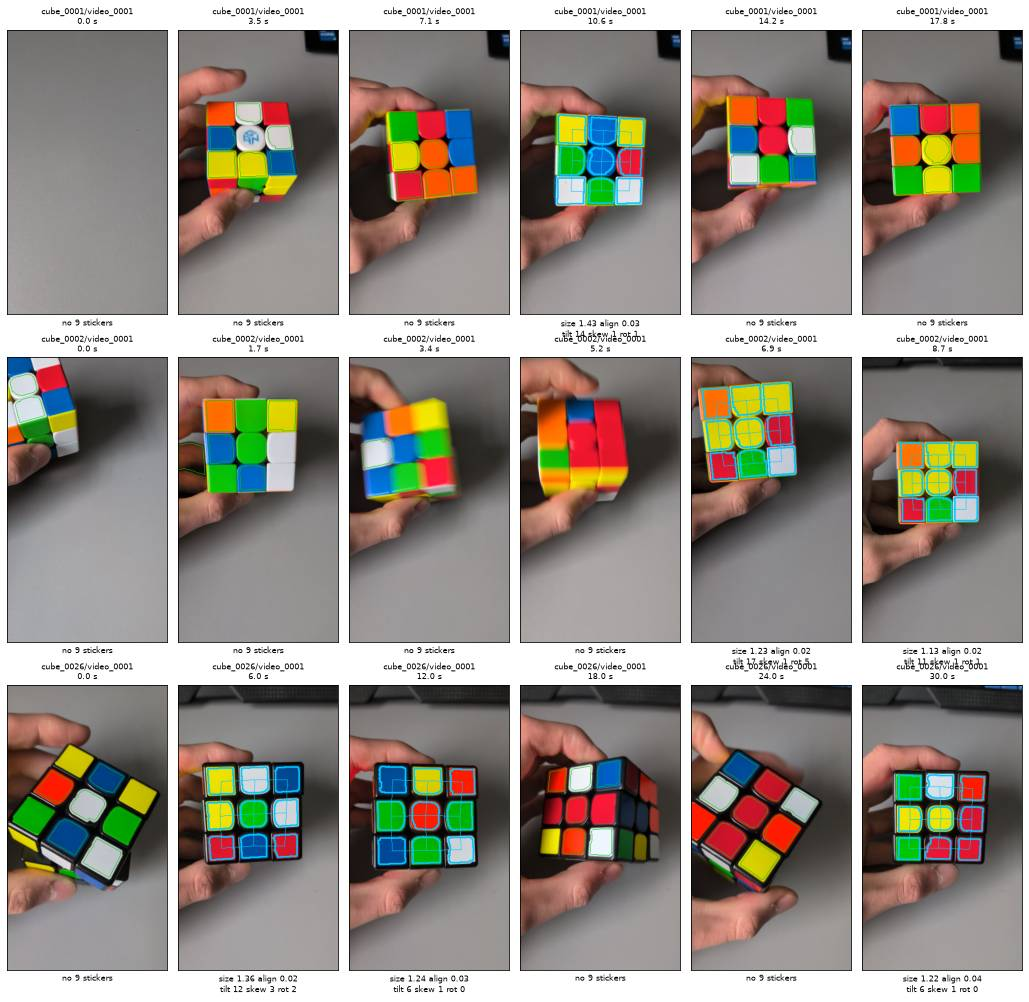

In [7]:
def draw_grid(frame, stickers, candidate, color, thickness=2):
    out = frame.copy()
    cv2.drawContours(out, stickers.contours, -1, ACCEPTED, 1)
    if candidate is not None:
        chosen = [stickers.contours[i] for i in candidate.order.ravel()]
        cv2.drawContours(out, chosen, -1, color, thickness)
        for line in [*candidate.points, *candidate.points.transpose(1, 0, 2)]:
            cv2.polylines(out, [np.int32(line)], False, color, 1)
    return out


def metrics_text(candidate):
    if candidate is None:
        return "no 9 stickers"
    m = candidate.metrics
    return (
        f"size {m['size']:.2f} align {m['align']:.2f}\n"
        f"tilt {m['tilt']:.0f} skew {m['skew']:.0f} rot {m['rotation']:.0f}"
    )


def frames_at(name, width, indices):
    wanted = set(indices)
    return {i: f for i, (_, f) in enumerate(frames(name, width)) if i in wanted}


SAMPLES_PER_VIDEO = 6
fig, axes = plt.subplots(
    len(VIDEOS), SAMPLES_PER_VIDEO, figsize=(2.4 * SAMPLES_PER_VIDEO, 4.6 * len(VIDEOS))
)
for row, name in zip(axes, VIDEOS.name, strict=True):
    analyzed = video_frames(name, DEFAULT)
    indices = np.linspace(0, len(analyzed) - 1, SAMPLES_PER_VIDEO).astype(int)
    images = frames_at(name, DEFAULT["width"], indices)
    for ax, i in zip(row, indices, strict=True):
        frame = analyzed[i]
        candidate = frame.candidates[0] if frame.candidates else None
        image = draw_grid(images[i], frame.stickers, candidate, CHOSEN)
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{name}\n{frame.t / 1000:.1f} s", fontsize=8)
        ax.set_xlabel(metrics_text(candidate), fontsize=8)
        ax.set_xticks([])
        ax.set_yticks([])
fig.tight_layout()
plt.show()

## Measurements

With the default detection, on all frames:

- **Sticker side / frame width** of the accepted contours: sets `sticker_min`, `sticker_max`
  (the face is about 3 sticker sides wide) and `width` (stickers of about 65-80 px, the size
  of the 3.2 photos at 750 px)
- **Frames with a candidate** (9 stickers) and the distribution of its gate metrics, for the
  frames with a well aligned candidate (align below the largest value of the grid)
- **Motion and color noise** between consecutive frames with such a candidate whose pitch
  changes less than 5 %: sets `motion` and `color`
- **Center colors**: distances between the centers of the 6 faces of each annotated cube in
  the photos (the closest pair is the limit for `dedup`), and between the centers of
  consecutive frames in the videos (same face, the noise). In the photos the color is the
  median over the annotated polygon shrunk to `PHOTO_SCALE` about its center (logos
  included: the annotations have no holes)

In [8]:
QUANTILES = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
width = DEFAULT["width"]
sides, metric_rows, noise_rows = [], [], []
for name in VIDEOS.name:
    analyzed = video_frames(name, DEFAULT)
    sides += list(np.sqrt(np.concatenate([f.stickers.areas for f in analyzed])) / width)
    aligned = [
        f.candidates[0] if f.candidates and f.metrics[0, 1] <= max(GRID["align"]) else None
        for f in analyzed
    ]
    metric_rows += [c.metrics for c in aligned if c is not None]
    for (f0, c0), (f1, c1) in itertools.pairwise(zip(analyzed, aligned, strict=True)):
        if c0 is None or c1 is None or abs(c1.pitch / c0.pitch - 1) > 0.05:
            continue
        colors0, colors1 = f0.stickers.colors[c0.order], f1.stickers.colors[c1.order]
        noise_rows.append(
            {
                "motion": np.linalg.norm(c1.points - c0.points, axis=2).max() / c1.pitch,
                "color": np.linalg.norm(colors1 - colors0, axis=2).max(),
                "center color": np.linalg.norm(colors1[1, 1] - colors0[1, 1]),
            }
        )
    with_candidate = sum(bool(f.candidates) for f in analyzed)
    print(f"{name}: {len(analyzed)} frames, {with_candidate} with 9 stickers or more")


PHOTO_WIDTH = 750  # px, as in 3.2
PHOTO_SCALE = 0.6  # annotated polygon shrunk about its center for the color


def photo_center_colors(p):
    """Center color of each annotated photo, cube_id -> list of 6"""
    lab_weight = [p["l_weight"], 1, 1]
    out = {}
    for image in annotated_images(CVAT_ANNOTATIONS):
        photo = cv2.imread(str(RAW_IMAGES_DIR / image.cube_id / image.file_name))
        scale = PHOTO_WIDTH / photo.shape[1]
        photo = cv2.resize(photo, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        lab = cv2.cvtColor(np.float32(photo) / 255, cv2.COLOR_BGR2Lab) * lab_weight
        sticker = image.stickers[grid_order([s.center for s in image.stickers])[4]]
        polygon = np.float32(sticker.polygon) * scale
        polygon = np.int32((polygon - polygon.mean(axis=0)) * PHOTO_SCALE + polygon.mean(axis=0))
        mask = np.zeros(lab.shape[:2], np.uint8)
        cv2.fillPoly(mask, [polygon], 1)
        out.setdefault(image.cube_id, []).append(np.median(lab[mask > 0], axis=0))
    return out


centers = photo_center_colors(DEFAULT)
center_distances = pd.Series(
    [
        np.linalg.norm(a - b)
        for colors in centers.values()
        for a, b in itertools.combinations(colors, 2)
    ]
)
closest = pd.Series(
    [
        min(np.linalg.norm(a - b) for a, b in itertools.combinations(colors, 2))
        for colors in centers.values()
    ]
)
display(
    pd.DataFrame(
        {
            "sticker side / width": pd.Series(sides).quantile(QUANTILES),
            **pd.DataFrame(metric_rows).quantile(QUANTILES).to_dict("series"),
            **pd.DataFrame(noise_rows).quantile(QUANTILES).to_dict("series"),
            "photos: centers of a cube": center_distances.quantile(QUANTILES),
            "photos: closest centers of a cube": closest.quantile(QUANTILES),
        }
    )
    .T.round(3)
    .rename_axis("quantile", axis=1)
)

cube_0001/video_0001: 179 frames, 66 with 9 stickers or more
cube_0002/video_0001: 88 frames, 38 with 9 stickers or more
cube_0026/video_0001: 301 frames, 167 with 9 stickers or more


quantile,0.05,0.25,0.50,0.75,0.95,0.99
sticker side / width,0.134,0.144,0.152,0.159,0.169,0.178
size,1.133,1.175,1.252,1.369,1.508,1.625
align,0.015,0.021,0.032,0.038,0.049,0.057
tilt,2.042,5.969,9.805,13.645,22.402,26.291
skew,0.218,0.949,1.532,2.432,5.252,7.613
rotation,0.256,0.851,1.737,3.329,6.842,13.226
motion,0.020,0.034,0.063,0.123,0.277,0.459
color,0.327,0.515,0.841,1.466,4.219,6.441
center color,0.000,0.016,0.332,0.872,3.158,5.327
photos: centers of a cube,21.026,56.779,83.344,112.966,139.283,162.373


## Gate and hysteresis

A frame passes if a candidate has every metric within its limit (skew within the `tilt`
limit). Outside a window the limits are `size_ratio`, `align`, `tilt`, `rotation`; within a
window they are loosened by `delta`: `x (1 + delta)`, for the size ratio its excess over 1,
`1 + (size_ratio - 1)(1 + delta)`. A face at the border of a limit does not restart the
window on every frame.

In [9]:
def limits(p, within):
    f = 1 + p["delta"] if within else 1
    return np.array(
        [
            1 + (p["size_ratio"] - 1) * f,
            p["align"] * f,
            p["tilt"] * f,
            p["tilt"] * f,
            p["rotation"] * f,
        ]
    )


def gate(frame, limit):
    """Index of the first candidate within the limits, -1 if none"""
    if not len(frame.metrics):
        return -1
    ok = (frame.metrics <= limit).all(axis=1)
    return int(ok.argmax()) if ok.any() else -1

## Stability window, capture, duplicates

Replay of the frames of a video:

1. **No window** – a frame passing the gate (strict limits) opens one.
2. **Within a window** – the gate with the loosened limits. A frame without a grid is
   skipped; the window is dropped once no grid was seen for more than `max_gap_ms`. A frame
   with a grid is stable if its centers moved at most `motion` x pitch from the previous
   frame of the window (centers matched by their row and column) and each sticker color is
   within `color` of its median over the window. An unstable frame drops the window and may
   open a new one (strict limits).
3. **Capture** – a frame added to the window is at least `hold_ms` after its first frame:
   the 9 colors are the medians of each sticker over the window. Captured if the center
   color is at least `dedup` from the center of every earlier capture, else a **duplicate**.
   Either way the window is closed; the next one starts with the next accepted frame.

In [10]:
class Capture(NamedTuple):
    first: int  # frame indices of the window
    last: int
    candidate: Candidate  # grid of the last frame
    colors: np.ndarray  # 3 x 3 x 3, medians over the window
    duplicate: bool


class Entry(NamedTuple):
    index: int
    candidate: Candidate
    colors: np.ndarray  # 3 x 3 x 3


def replay(analyzed, p, trace=None):
    """Captures and duplicates; trace: list filled with a row per frame"""
    strict, loose = limits(p, False), limits(p, True)
    events, window = [], []
    for i, frame in enumerate(analyzed):
        motion = color = np.nan
        pick = gate(frame, loose if window else strict)
        if window and pick < 0 and frame.t - analyzed[window[-1].index].t > p["max_gap_ms"]:
            window = []
        if window and pick >= 0:
            candidate = frame.candidates[pick]
            colors = frame.stickers.colors[candidate.order]
            median = np.median([e.colors for e in window], axis=0)
            motion = np.linalg.norm(candidate.points - window[-1].candidate.points, axis=2).max()
            motion /= candidate.pitch
            color = np.linalg.norm(colors - median, axis=2).max()
            if motion <= p["motion"] and color <= p["color"]:
                window.append(Entry(i, candidate, colors))
            else:
                window = []
                pick = gate(frame, strict)
        if not window and pick >= 0:
            candidate = frame.candidates[pick]
            window = [Entry(i, candidate, frame.stickers.colors[candidate.order])]
        event = None
        held = window and window[-1].index == i  # a frame without a grid does not capture
        if held and frame.t - analyzed[window[0].index].t >= p["hold_ms"]:
            colors = np.median([e.colors for e in window], axis=0)
            duplicate = any(
                np.linalg.norm(colors[1, 1] - e.colors[1, 1]) < p["dedup"]
                for e in events
                if not e.duplicate
            )
            event = Capture(window[0].index, i, window[-1].candidate, colors, duplicate)
            events.append(event)
            window = []
        if trace is not None:
            best = frame.candidates[0].metrics if frame.candidates else {}
            trace.append(
                {"t": frame.t / 1000, "motion": motion, "color": color}
                | {m: best.get(m, np.nan) for m in GATE}
                | {"passed": pick >= 0, "window": bool(window) or event is not None}
                | {
                    "event": ""
                    if event is None
                    else ("duplicate" if event.duplicate else "capture")
                }
            )
    return events

## All combinations

For every combination: the captures (without duplicates) and the duplicates per video. A
video is right with exactly `FACES` captures. Sorted by the right videos, then by the total
distance from `FACES` captures.

In [11]:
replay_grid = {k: v for k, v in GRID.items() if k not in DETECTION}
rows = []
for detection in tqdm(combinations({k: GRID[k] for k in DETECTION}), desc="replay"):
    analyzed = {name: video_frames(name, detection) for name in VIDEOS.name}
    for rest in combinations(replay_grid):
        p = detection | rest
        row = dict(p)
        for name, video in analyzed.items():
            events = replay(video, p)
            row[name] = sum(not e.duplicate for e in events)
            row[f"{name} duplicates"] = sum(e.duplicate for e in events)
        rows.append(row)
results = pd.DataFrame(rows)
counts = results[list(VIDEOS.name)]
results["right videos"] = (counts == FACES).sum(axis=1)
results["off"] = (counts - FACES).abs().sum(axis=1)
results = results.sort_values(["right videos", "off"], ascending=[False, True])
tested = [k for k, v in GRID.items() if len(v) > 1]
display(results[tested + list(VIDEOS.name) + ["right videos", "off"]].head(15))

replay:   0%|          | 0/6 [00:00<?, ?it/s]

replay:  17%|█▋        | 1/6 [00:13<01:08, 13.73s/it]

replay:  33%|███▎      | 2/6 [00:26<00:53, 13.28s/it]

replay:  50%|█████     | 3/6 [00:36<00:34, 11.56s/it]

replay:  67%|██████▋   | 4/6 [00:49<00:24, 12.17s/it]

replay:  83%|████████▎ | 5/6 [00:57<00:10, 10.72s/it]

replay: 100%|██████████| 6/6 [01:10<00:00, 11.55s/it]

replay: 100%|██████████| 6/6 [01:10<00:00, 11.77s/it]

,width,hull,size_ratio,align,tilt,rotation,delta,motion,color,hold_ms,max_gap_ms,dedup,cube_0001/video_0001,cube_0002/video_0001,cube_0026/video_0001,right videos,off
146,300,False,1.5,0.1,25,10,0.0,0.1,4.0,300,200,6.0,5,4,5,0,4
147,300,False,1.5,0.1,25,10,0.0,0.1,4.0,300,200,10.0,5,4,5,0,4
154,300,False,1.5,0.1,25,10,0.0,0.1,8.0,300,200,6.0,5,4,5,0,4
155,300,False,1.5,0.1,25,10,0.0,0.1,8.0,300,200,10.0,5,4,5,0,4
178,300,False,1.5,0.1,25,10,0.3,0.1,4.0,300,200,6.0,5,4,5,0,4
179,300,False,1.5,0.1,25,10,0.3,0.1,4.0,300,200,10.0,5,4,5,0,4
186,300,False,1.5,0.1,25,10,0.3,0.1,8.0,300,200,6.0,5,4,5,0,4
187,300,False,1.5,0.1,25,10,0.3,0.1,8.0,300,200,10.0,5,4,5,0,4
210,300,False,1.5,0.1,25,20,0.0,0.1,4.0,300,200,6.0,5,4,5,0,4
211,300,False,1.5,0.1,25,20,0.0,0.1,4.0,300,200,10.0,5,4,5,0,4


Effect of each tested parameter: mean over all combinations with that value.

In [12]:
display(
    pd.concat(
        {
            k: results.groupby(k)[["right videos", "off", *VIDEOS.name]].mean().rename(index=str)
            for k in tested
        }
    ).round(2)
)

right videos    off  cube_0001/video_0001  \
width      300             0.0  10.03                  3.35   
           360             0.0  10.11                  3.38   
           450             0.0  11.37                  2.12   
hull       False           0.0  10.97                  2.24   
           True            0.0  10.03                  3.66   
size_ratio 1.5             0.0  10.45                  2.94   
           2.0             0.0  10.50                  2.96   
           2.5             0.0  10.56                  2.96   
align      0.1             0.0  10.50                  2.95   
           0.2             0.0  10.50                  2.95   
tilt       15              0.0  11.00                  2.95   
           25              0.0  10.00                  2.95   
rotation   10              0.0  10.50                  2.95   
           20              0.0  10.50                  2.95   
delta      0.0             0.0  10.71                  2.94   
           0.3             0.0  10.29                  2.96   
motion     0.05            0.0  12.49                  2.38   
           0.1             0.0   8.51                  3.53   
color      4.0             0.0  10.61                  2.95   
           8.0             0.0  10.39                  2.95   
hold_ms    300             0.0   8.08                  3.50   
           600             0.0  12.92                  2.40   
max_gap_ms 0               0.0  10.91                  2.82   
           200             0.0  10.09                  3.08   
dedup      6.0             0.0  10.50                  2.95   
           10.0            0.0  10.50                  2.95   

                  cube_0002/video_0001  cube_0026/video_0001  
width      300                    1.11                  3.51  
           360                    1.09                  3.42  
           450                    1.02                  3.49  
hull       False                  1.06                  3.73  
           True                   1.09                  3.22  
size_ratio 1.5                    1.07                  3.54  
           2.0                    1.07                  3.47  
           2.5                    1.07                  3.41  
align      0.1                    1.07                  3.48  
           0.2                    1.07                  3.47  
tilt       15                     0.79                  3.26  
           25                     1.35                  3.69  
rotation   10                     1.07                  3.47  
           20                     1.07                  3.47  
delta      0.0                    0.85                  3.49  
           0.3                    1.29                  3.46  
motion     0.05                   0.50                  2.63  
           0.1                    1.65                  4.32  
color      4.0                    1.01                  3.43  
           8.0                    1.14                  3.52  
hold_ms    300                    2.05                  4.36  
           600                    0.09                  2.59  
max_gap_ms 0                      1.04                  3.23  
           200                    1.11                  3.72  
dedup      6.0                    1.07                  3.47  
           10.0                   1.07                  3.47

## One combination in detail

`SHOW`: the best combination of the table (change it to look at another one). Per video:

- the frame at the end of each capture window with its grid and the 9 median colors;
  duplicates are only counted (a face held after its capture is one every `hold_ms`)
- the timeline: the gate metrics of the candidate with the smallest align (dashed: strict
  limit, dotted: loosened), the motion and color within windows; windows shaded, captures
  green, duplicates orange

{'width': 300, 'blur': 3, 'canny_low': 40, 'canny_ratio': 2, 'dilation': 5, 'rect_ratio': 1.38, 'm3_fraction': 0.1, 'gamma_max': 0.2, 'sticker_min': 0.08, 'sticker_max': 0.25, 'hull': False, 'color_erosion': 0.1, 'l_weight': 0.3, 'size_ratio': 1.5, 'align': 0.1, 'tilt': 25, 'rotation': 10, 'delta': 0.0, 'motion': 0.1, 'color': 4.0, 'hold_ms': 300, 'max_gap_ms': 200, 'dedup': 6.0}


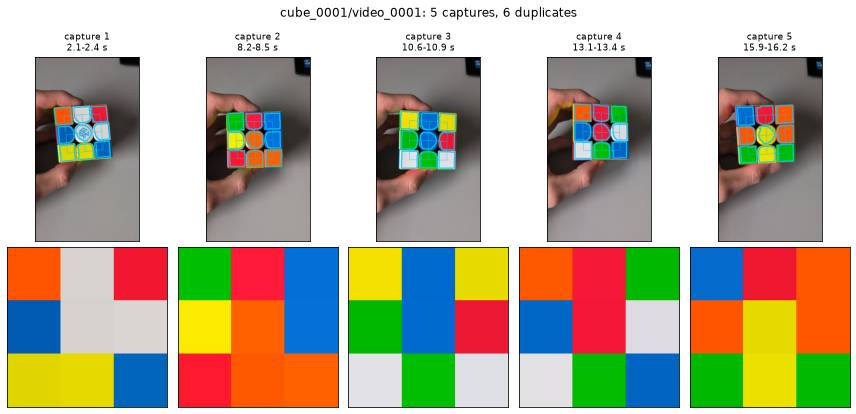

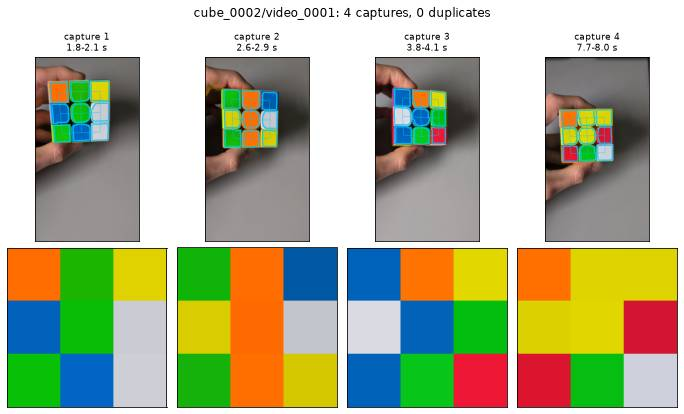

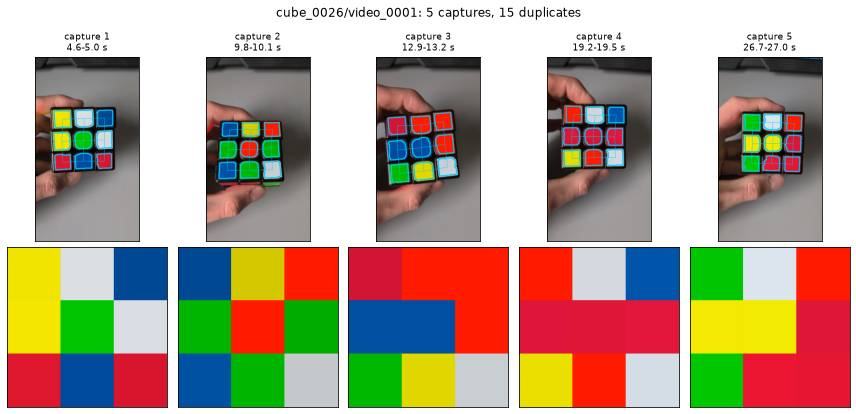

In [13]:
SHOW = {k: results.iloc[0][k] for k in GRID}
SHOW = {k: type(GRID[k][0])(v) for k, v in SHOW.items()}
print(SHOW)


def swatch(colors, p, size=40):
    lab = np.float32(colors / [p["l_weight"], 1, 1])
    bgr = cv2.cvtColor(lab, cv2.COLOR_Lab2BGR)
    return cv2.resize(np.uint8(np.clip(bgr, 0, 1) * 255), (3 * size, 3 * size), interpolation=0)


for name in VIDEOS.name:
    analyzed = video_frames(name, SHOW)
    events = replay(analyzed, SHOW)
    captures = [e for e in events if not e.duplicate]
    duplicates = len(events) - len(captures)
    if not captures:
        print(f"{name}: no captures, {duplicates} duplicates")
        continue
    images = frames_at(name, SHOW["width"], [e.last for e in captures])
    fig, axes = plt.subplots(2, len(captures), figsize=(2.4 * len(captures), 6), squeeze=False)
    for k, event in enumerate(captures):
        frame = analyzed[event.last]
        image = draw_grid(images[event.last], frame.stickers, event.candidate, CHOSEN)
        axes[0, k].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        t0, t1 = analyzed[event.first].t / 1000, frame.t / 1000
        axes[0, k].set_title(f"capture {k + 1}\n{t0:.1f}-{t1:.1f} s", fontsize=9)
        axes[1, k].imshow(cv2.cvtColor(swatch(event.colors, SHOW), cv2.COLOR_BGR2RGB))
        for ax in axes[:, k]:
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle(f"{name}: {len(captures)} captures, {duplicates} duplicates")
    fig.tight_layout()
    plt.show()

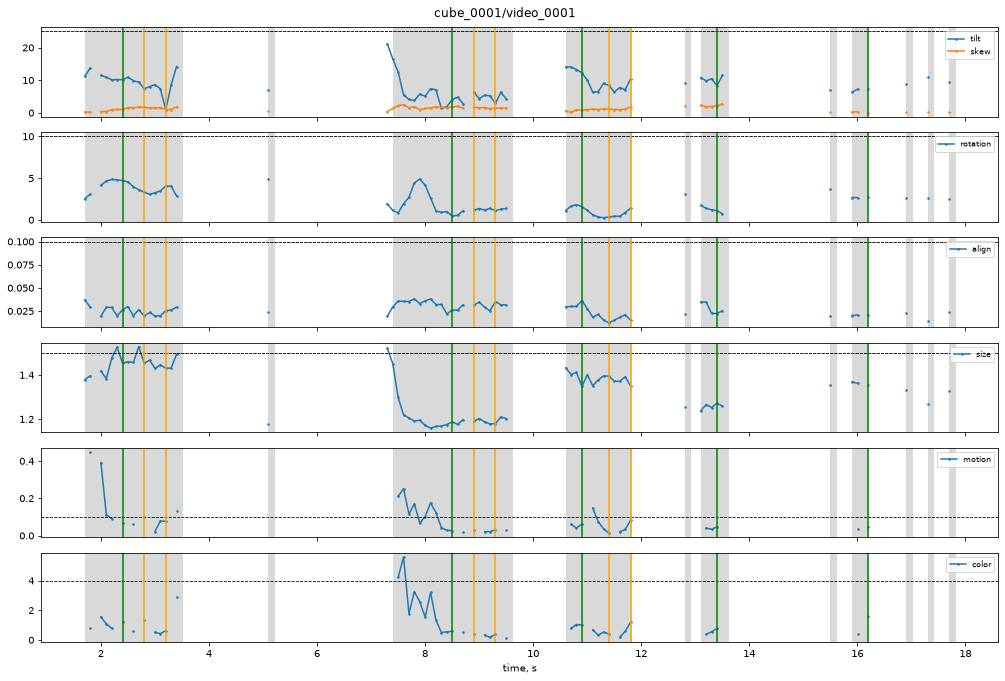

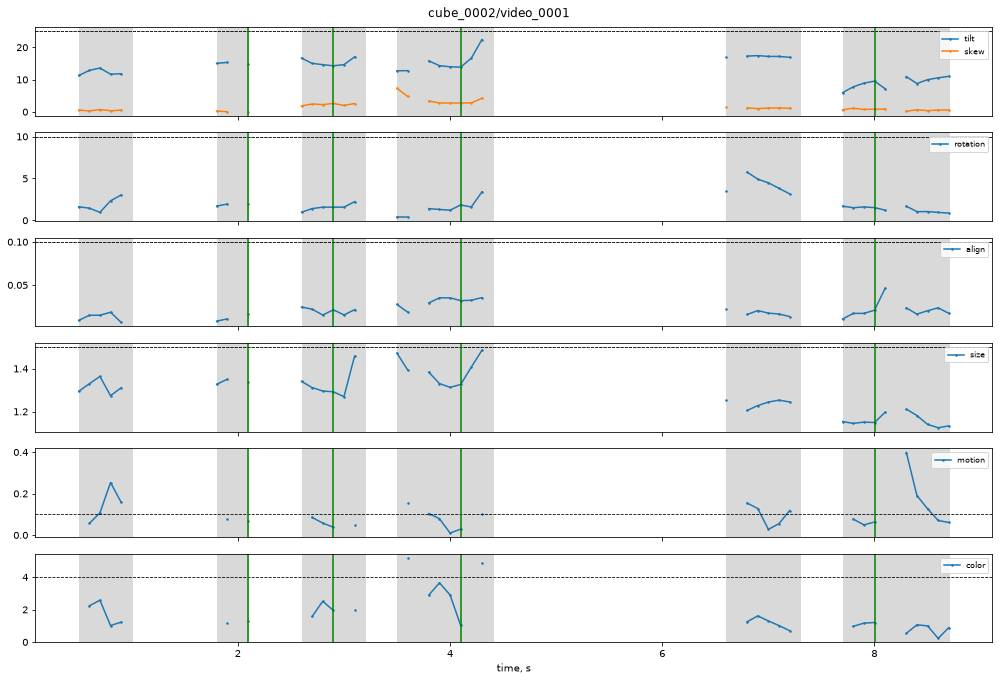

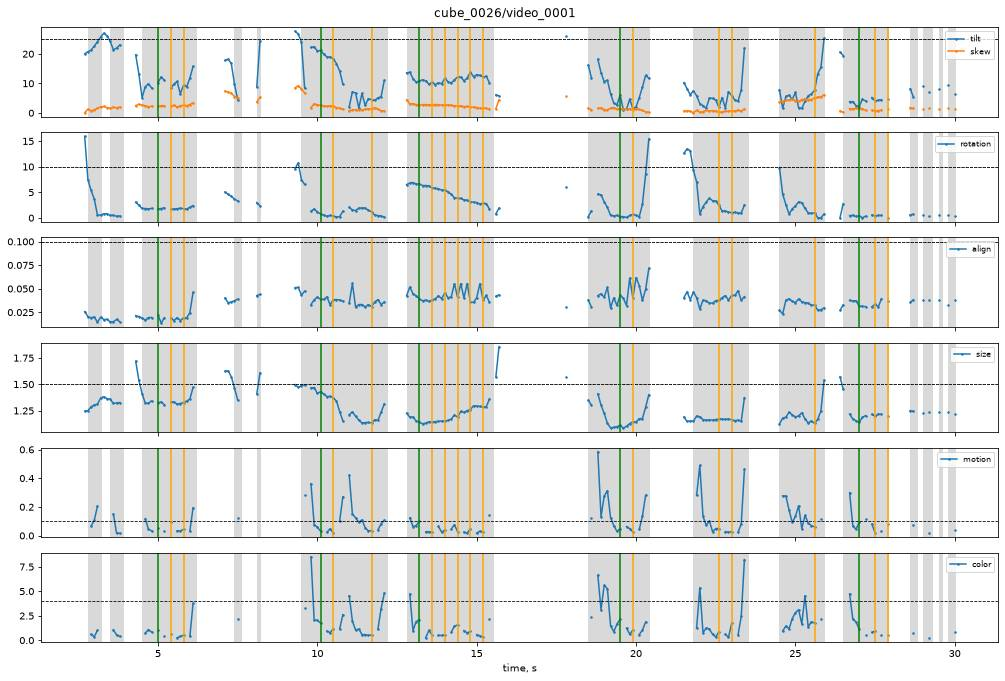

In [14]:
def timeline(name, p):
    trace = []
    replay(video_frames(name, p), p, trace)
    df = pd.DataFrame(trace)
    strict, loose = limits(p, False), limits(p, True)
    panels = [
        (["tilt", "skew"], 2),
        (["rotation"], 4),
        (["align"], 1),
        (["size"], 0),
        (["motion"], None),
        (["color"], None),
    ]
    fig, axes = plt.subplots(len(panels), 1, figsize=(14, 1.6 * len(panels)), sharex=True)
    for ax, (columns, limit) in zip(axes, panels, strict=True):
        for column in columns:
            ax.plot(df.t, df[column], ".-", markersize=3, label=column)
        if limit is not None:
            ax.axhline(strict[limit], color="k", linestyle="--", linewidth=0.8)
            ax.axhline(loose[limit], color="k", linestyle=":", linewidth=0.8)
        else:
            ax.axhline(p[columns[0]], color="k", linestyle="--", linewidth=0.8)
        ax.fill_between(
            df.t, 0, 1, where=df.window, color="0.85", transform=ax.get_xaxis_transform()
        )
        for t, event in zip(df.t, df.event, strict=True):
            if event:
                ax.axvline(t, color="g" if event == "capture" else "orange", linewidth=1.5)
        ax.legend(loc="upper right", fontsize=8)
    axes[-1].set_xlabel("time, s")
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()


for name in VIDEOS.name:
    timeline(name, SHOW)

Videos of the replay with `SHOW`, written to `data/interim/auto_capture/` (not in git): the
grid of the gate in blue within a window, red when no candidate passes (the one with the
smallest align), metrics and the number of captures; a capture frame has a green border, a
duplicate an orange one.

In [15]:
OUT_DIR = INTERIM_DATA_DIR / "auto_capture"
OUT_DIR.mkdir(parents=True, exist_ok=True)
for name in VIDEOS.name:
    analyzed = video_frames(name, SHOW)
    trace = []
    replay(analyzed, SHOW, trace)
    path = OUT_DIR / f"{name.replace('/', '_')}.mp4"
    writer = None
    captures = 0
    for (_, image), frame, row in zip(frames(name, SHOW["width"]), analyzed, trace, strict=True):
        pick = gate(frame, limits(SHOW, row["window"]))
        candidate = frame.candidates[max(pick, 0)] if frame.candidates else None
        out = draw_grid(image, frame.stickers, candidate, CHOSEN if pick >= 0 else FAILED)
        captures += row["event"] == "capture"
        lines = [*metrics_text(candidate).split("\n"), f"captures {captures}"]
        for k, line in enumerate(lines):
            cv2.putText(out, line, (5, 20 + 18 * k), 0, 0.5, (255, 255, 255), 2)
            cv2.putText(out, line, (5, 20 + 18 * k), 0, 0.5, (0, 0, 0), 1)
        if row["event"]:
            border = (0, 200, 0) if row["event"] == "capture" else (0, 140, 255)
            cv2.rectangle(out, (0, 0), (out.shape[1] - 1, out.shape[0] - 1), border, 8)
        if writer is None:
            fourcc = cv2.VideoWriter.fourcc(*"mp4v")
            writer = cv2.VideoWriter(str(path), fourcc, FPS, out.shape[1::-1])
        writer.write(out)
    if writer is not None:
        writer.release()
    print(path)

/home/wyrzykowski/praca-inzynierska/puzzle-vision/research/data/interim/auto_capture/cube_0001_video_0001.mp4


/home/wyrzykowski/praca-inzynierska/puzzle-vision/research/data/interim/auto_capture/cube_0002_video_0001.mp4


/home/wyrzykowski/praca-inzynierska/puzzle-vision/research/data/interim/auto_capture/cube_0026_video_0001.mp4
